## Data Gathering



*   Use DuckDuckGo for downloading images



In [2]:
%pip install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 16.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ddgs]




* Download images, based on keyword, for training and validation. The variable `results` below will contain a list of image URLs that is compatible with `fastai`'s `download_images()`.

The main application of this model that will be trained here is for detecting roads with available public parking. Hence, the terms below are sample keywords that would display roads with free parking spots:
* "street parking available"
* "road with empty parking spaces"
* "open roadside parking"
* "empty curbside parking"
* "vacant parking spots on street"

On the other hand, here are the keywords that would results to images of roads with automobiles already parked:
* “street with parked cars”
* “cars parked along the road”
* “roadside parking with cars”
* “curbside parking with vehicles”
* “cars parked on street side”

Based on our application, we can categorize three types of parking:
* residential - refers to the parking spaces in the neighborhood, this include cul de sacs.
* commercial - refers to the parking spaces where businesses rely on customer parking; this usually refers to the avenue or boulevard designated parking lanes.
* informal - refers to ordinary grass or dirt side of the road which are not designated as parking but commonly used as temporary stops.


In [8]:
from ddgs import DDGS
from pathlib import Path
from fastai.vision.all import *

def search_images(keyword, max_images=100):
    with DDGS() as ddgs:
        results = ddgs.images(
            query = keyword,
            max_results = max_images
        )
    return [result["image"] for result in results]

results = search_images("vacant parking spots on the street")


parking_types = ("residential", "commercial", "informal")
path = Path("parking")
path.mkdir(exist_ok=True)

for parking_type in parking_types:
    dest = path / parking_type
    dest.mkdir(exist_ok=True)

    print(f"Searching for {parking_type} parking images...")

    results = search_images(
        f"{parking_type} parking",
        max_images=100
    )

    # fastai API download_images() has the ff features:
    #     - Fetching each image from the web
    #     - Saving it to a local directory
    #     - Skipping or reporting failed downloads
    #     - Optionally resizing or converting formats after download
    download_images(dest, urls=results)
    print(f"Finished downloading {parking_type} images")

# fastai API to remove unredable or corrupt images
failed = verify_images(get_image_files(path))

for image in failed:
    image.unlink()

print(f"Removed {len(failed)} invalid images")
print(f"Total valid images: {len(get_image_files(path))}")

Searching for residential parking images...
Finished downloading residential images
Searching for commercial parking images...
Finished downloading commercial images
Searching for informal parking images...
Finished downloading informal images
Removed 4 invalid images
Total valid images: 165


`DataBlock` is a fastai API used to group datasets by describing the pipeline instead of manually coding each line of code.

In the code below, I have two datasets, one for input and one for output.
* ImageBlock tells us that each item for the input is an image.
* CategoryBlock tells us that the label is a category.

The input to `get_items` is a list of URLs specifying the location of each image.

`RandomSplitter(valid_pct=0.2)` tells us that 20% of the items are reserved for validation set.

`get_y` tells us how to assign label to each item. The input `parent_label` means we use the containing folder name as the label and this is common in image classification problem.

`item_tfms=...` allows transformations to be applied on each item individually.

In [10]:
parkings = DataBlock(
    blocks = (ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(128)
)


A `DataLoader` class is a PyTorch class that handles the mechanics of feeding data to your model. Its main functions are:
* Batching — It automatically groups samples into batches, which improves training stability and GPU utilization.
* Shuffling — It randomizes sample order each epoch to reduce overfitting and improve generalization.
* Parallel Loading — It uses multiple worker processes (num_workers) to load and preprocess data concurrently, preventing the CPU from becoming a bottleneck.

In the code below, `path` contains the location of the data.

The `.dataloaders(path)` tells fastai to apply the DataBlock specifications to the data pointed by the `path`.

`dls.show_batch(max_n=9)` tells fastai to take one batch from the training DataLoader and display it using Fastai’s built‑in visualization tools.

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


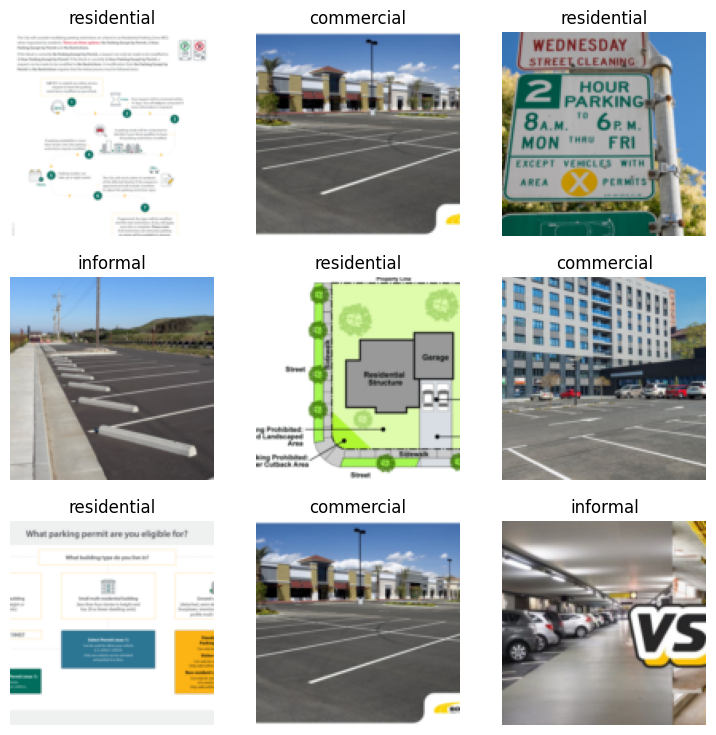

In [11]:
## DataLoaders
dls = parkings.dataloaders(path)
dls.show_batch(max_n=9)